Задача 1: реализовать serial test и применить к выборке samples

In [29]:
import numpy as np
from scipy.stats import chi2
def rng(m=2**32, a=1103515245, c=12345):
    rng.current = (a * rng.current + c) % m
    return rng.current / m

rng.current = 1

[rng() for _ in range(10)]

samples = [rng() for _ in range(1000)]

pairs = np.array(samples).reshape(-1, 2)

k = 5

counts, _, _ = np.histogram2d(
    pairs[:, 0],
    pairs[:, 1],
    bins=k,
    range=[[0, 1], [0, 1]]
)

expected = len(pairs) / (k * k)

T = np.sum((counts - expected)**2 / expected)

p_value = chi2.sf(T, k*k - 1)

print("Частоты по клеткам:")
print(counts)
print("Сумма частот:", counts.sum())
print("Статистика:", T)
print("p-value:", p_value)

if p_value < 0.05:
    print("Гипотеза отвергается")
else:
    print("Нет оснований отвергнуть гипотезу")



Частоты по клеткам:
[[28. 13. 24. 20. 16.]
 [18. 20. 22. 19. 23.]
 [21. 13. 17. 21. 14.]
 [16. 23. 27. 16. 17.]
 [22. 20. 22. 20. 28.]]
Сумма частот: 500.0
Статистика: 21.5
p-value: 0.6090827152142755
Нет оснований отвергнуть гипотезу


Задача 2: Реализовать permutation test и применить к выборке samples

In [30]:
import numpy as np
from scipy.stats import chi2
from itertools import permutations

d = 3

n = len(samples) // d

groups = np.array(samples[:n*d]).reshape(n, d)

orders = np.argsort(groups, axis=1)

all_orders = list(permutations(range(d)))

counts = []

for order in all_orders:
    count = np.sum(np.all(orders == order, axis=1))
    counts.append(int(count))

expected = n / len(all_orders)

T = np.sum((np.array(counts) - expected)**2 / expected)

p_value = chi2.sf(T, len(all_orders) - 1)

print("Частоты перестановок:", counts)
print("Сумма частот:", sum(counts))
print("Статистика:", T)
print("p-value:", p_value)

if p_value < 0.05:
    print("Гипотеза отвергается")
else:
    print("Нет оснований отвергнуть гипотезу")


Частоты перестановок: [54, 69, 52, 56, 47, 55]
Сумма частот: 333
Статистика: 4.855855855855856
p-value: 0.4337239950364655
Нет оснований отвергнуть гипотезу


Задача 3: Привести статистический тест, который покажет, что с rng_bad есть проблемы, а с rng - нет.

In [31]:
import numpy as np
from scipy.stats import binomtest

def rng(m=2**32, a=1103515245, c=12345):
    rng.current = (a * rng.current + c) % m
    return rng.current / m

def rng_bad(m=2**31, a=65539, c=0):
    rng_bad.current = (a * rng_bad.current + c) % m
    return rng_bad.current / m

rng.current = 1
rng_bad.current = 1

def test(generator):
    generator.current = 1

    samples = np.array([generator() for _ in range(30000)])

    triples = samples.reshape(-1, 3)

    y = 9*triples[:, 0] - 6*triples[:, 1] + triples[:, 2]

    d = np.abs(y - np.round(y))

    count = np.sum(d < 0.01)

    p_value = binomtest(
        int(count), len(triples), 0.02,
        alternative='greater'
    ).pvalue

    return int(count), p_value

count1, p1 = test(rng)
count2, p2 = test(rng_bad)

print("rng:")
print("Число попаданий:", count1)
print("p-value:", p1)

print("\nrng_bad:")
print("Число попаданий:", count2)
print("p-value:", p2)

print("\nРезультат:")
print("rng:", "отвергается" if p1 < 0.05 else "не отвергается")
print("rng_bad:", "отвергается" if p2 < 0.05 else "не отвергается")



rng:
Число попаданий: 210
p-value: 0.24674968896579647

rng_bad:
Число попаданий: 10000
p-value: 0.0

Результат:
rng: не отвергается
rng_bad: отвергается


Задача 4: Смоделировать выборку объема 1000 из дискретного распределения на множестве цифр 0, 1, 2, ..., 9 с весами 0.12, 0.3, 0.167, 0.24, 0.31, 0.54, 0.111, 0.02, 0.001, 0.2. По выборке построить гистограмму. Оптимизируйте алгоритм, упорядочив веса.

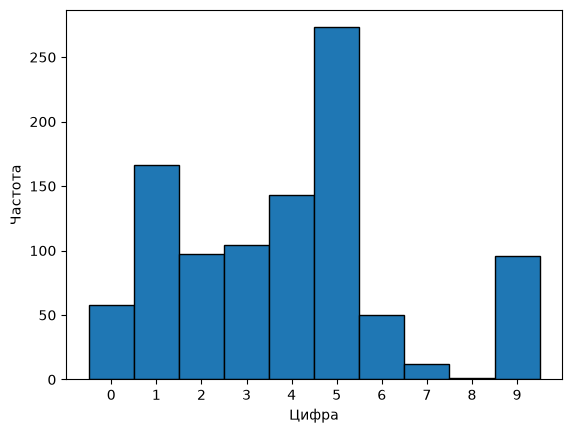

In [32]:
import numpy as np
import matplotlib.pyplot as plt

weights = np.array([0.12, 0.3, 0.167, 0.24, 0.31, 0.54, 0.111, 0.02, 0.001, 0.2])
p = weights / np.sum(weights)

order = np.argsort(-p)
p = p[order]
digits = np.arange(10)[order]
bounds = np.cumsum(p)

samples = []

for i in range(1000):
    u = np.random.random()

    for j in range(10):
        if u < bounds[j]:
            samples.append(digits[j])
            break


plt.hist(samples, bins=np.arange(11)-0.5, edgecolor='black')
plt.xticks(range(10))
plt.xlabel("Цифра")
plt.ylabel("Частота")
plt.show()

Задача 5: 
Смоделируйте выборку размера 1000 из распределения  𝐸𝑥𝑝(𝜆)  с помощью метода Inverse transform. Постройте выборочную гистограмму и точный график плотности распределения.

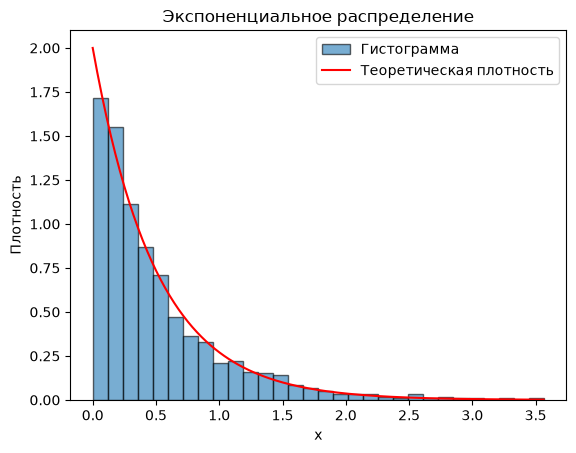

In [33]:
import numpy as np
import matplotlib.pyplot as plt

lam = 2

u = np.random.random(1000)

#вычисленная обратная функция распределения
samples = - np.log(1-u)/lam

plt.hist(samples, bins=30, density=True,
         alpha=0.6, edgecolor='black',
         label='Гистограмма')

x = np.linspace(0, max(samples), 200)
f = lam * np.exp(-lam * x)

plt.plot(x, f, color='red', label='Теоретическая плотность')
plt.xlabel('x')
plt.ylabel('Плотность')
plt.title('Экспоненциальное распределение')
plt.legend()
plt.show()

Задача 6: Обоснуйте (устно), что метод accept-reject действительно производит выборку из нужного распределения. Смоделируйте 1000 точек из распределения с плотностью  𝑒𝑥𝑐𝑜𝑠2𝑥  на отрезке  [−𝜋/2,𝜋/2] . По выборке постройте график выборочной гистограммы и сравните его с графиком точной функции плотности.

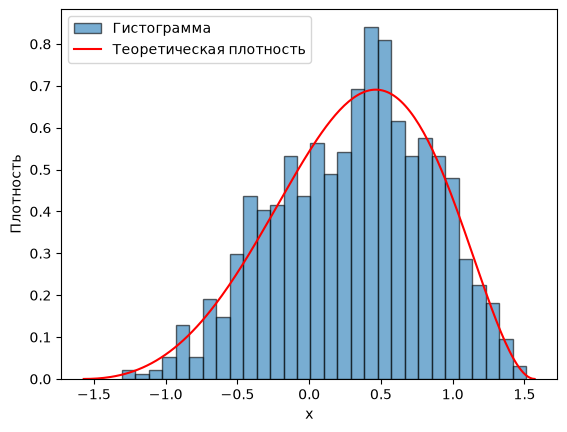

In [34]:
import numpy as np
import matplotlib.pyplot as plt
a = -np.pi/2
b = np.pi/2

#максимум плотности
M = 4/5 * np.exp(np.arctan(1/2))

def g(x):
    return np.exp(x) * np.cos(x)**2

samples = []

while len(samples) < 1000:
    u = np.random.uniform(a,b)
    v = np.random.uniform(0,M)

    if v <= g(u):
        samples.append(u)

C = 5 / (2* (np.exp(b) - np.exp(a)))

x = np.linspace(a,b,200)
f = C * g(x)

plt.hist(samples, bins=30, density=True,
         alpha=0.6, edgecolor='black',
         label='Гистограмма')

plt.plot(x, f, color='red',
         label='Теоретическая плотность')

plt.xlabel('x')
plt.ylabel('Плотность')
plt.legend()
plt.show()


Задача 7: Смоделировать и изобразить выборку из 500 точек равномерно распределенных внутри данного треугольника без использования метода отбора.


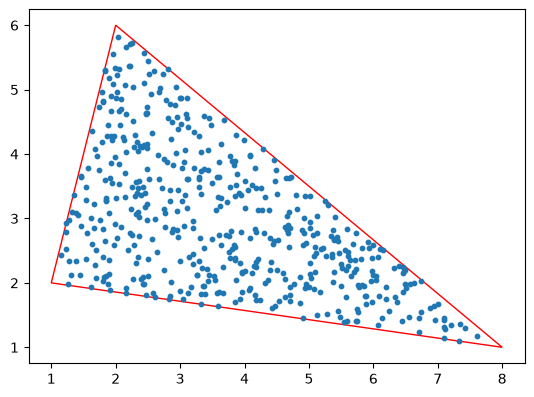

In [35]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon


A = np.array([1, 2])
B = np.array([2, 6])
C = np.array([8, 1])

u = np.random.random(500)
v = np.random.random(500)


x = np.sqrt(u) * (1 - v)
y = np.sqrt(u) * v

px = A[0] + x*(B[0]-A[0]) + y*(C[0]-A[0])
py = A[1] + x*(B[1]-A[1]) + y*(C[1]-A[1])

polygon = Polygon([A, B, C], closed=True,
                  fill=False, edgecolor='red')

fig, ax = plt.subplots()
ax.add_patch(polygon)

ax.scatter(px, py, s=10)

ax.set_aspect('equal')
plt.show()


Задание 8: Смоделировать без использования метода отбора выборку из 500 точек равномерно распределенных внутри единичного круга. Изобразите полученные точки. Они действительно равномерно заполняют круг? P.S. тут не до конца разобрался в условии сделал равномерное(чтобы площади соотносились), но возможно требовалось отобразить без учета соотношения площадей, тогда в центре было бы больше точек и распределение не было бы равномерным

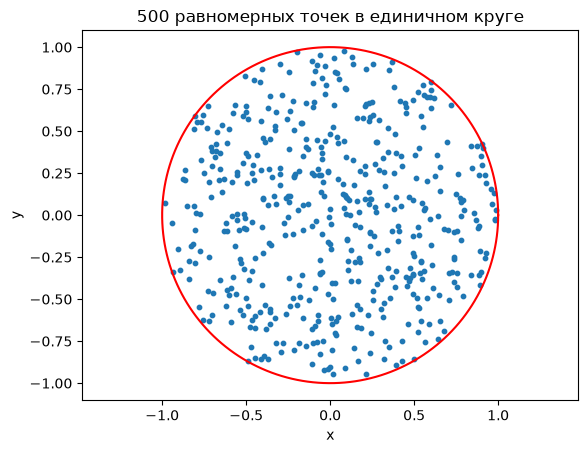

In [36]:

import numpy as np
import matplotlib.pyplot as plt

u = np.random.random(500)
v = np.random.random(500)

r = np.sqrt(u)
phi = 2 * np.pi * v

x = r * np.cos(phi)
y = r * np.sin(phi)

plt.scatter(x, y, s=10)

t = np.linspace(0, 2*np.pi, 200)
plt.plot(np.cos(t), np.sin(t), color='red')

plt.axis('equal')
plt.xlabel('x')
plt.ylabel('y')
plt.title('500 равномерных точек в единичном круге')
plt.show()


Задача 9: Докажите (устно), что приведенный ниже алгоритм (Box-Muller algorithm) формирует выборку из независимых N(0,1) случаных величин. Модифицируйте метод, чтобы исключить вызовы тригонометрических функций np.sin и np.cos. С помощью модифицированного метода смоделируйте выборку объема 1000 из двумерного гауссовского распределения со средним [4, 7] и ковариационной матрицей [[20, -4], [ -4, 40]]. Постройте 2D гистограмму полученного распределения. Сравните выборочное среднее и ковариационную матрицу с точными значениями.

Теоретическое среднее: [4 7]
Выборочное среднее: [4.18712811 7.06529717]

Теоретическая ковариационная матрица:
[[20 -4]
 [-4 40]]

Выборочная ковариационная матрица:
[[17.71090863 -3.76658434]
 [-3.76658434 40.70730518]]


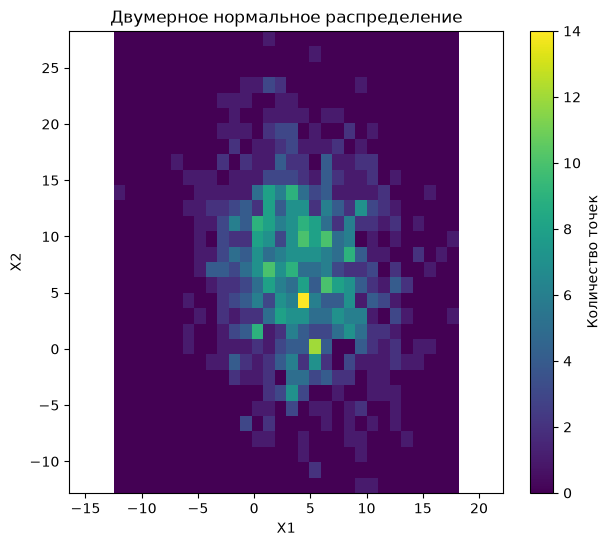

In [37]:
import numpy as np
import matplotlib.pyplot as plt

n = 1000

z = []

while len(z) < n:
    a = np.random.uniform(-1, 1)
    b = np.random.uniform(-1, 1)

    s = a**2 + b**2

    if s == 0 or s >= 1:
        continue

    k = np.sqrt(-2 * np.log(s) / s)

    z.append([a * k, b * k])

z = np.array(z)

mu = np.array([4, 7])

sigma = np.array([[20, -4],
                  [-4, 40]])

L = np.linalg.cholesky(sigma)

samples = z @ L.T + mu

mean = np.mean(samples, axis=0)

cov = np.cov(samples, rowvar=False)

print("Теоретическое среднее:", mu)
print("Выборочное среднее:", mean)

print("\nТеоретическая ковариационная матрица:")
print(sigma)

print("\nВыборочная ковариационная матрица:")
print(cov)

plt.figure(figsize=(7, 6))

plt.hist2d(samples[:, 0], samples[:, 1], bins=30)

plt.colorbar(label="Количество точек")
plt.xlabel("X1")
plt.ylabel("X2")
plt.title("Двумерное нормальное распределение")
plt.axis("equal")

plt.show()


Задача 10: Реализовать метод генерации случайного разбиения n-элементного множества на подмножества. С его помощью оценить ожидаемое число подмножеств в случайном разбиении множества из 100 элементов.

Число подмножеств: 28
Первые 5 подмножеств: [[15, 17], [62, 90], [18, 41, 46, 54, 85], [10, 28, 43, 69, 83], [39, 49, 50, 73, 87, 91]]
Оценка среднего числа подмножеств: 28.5946


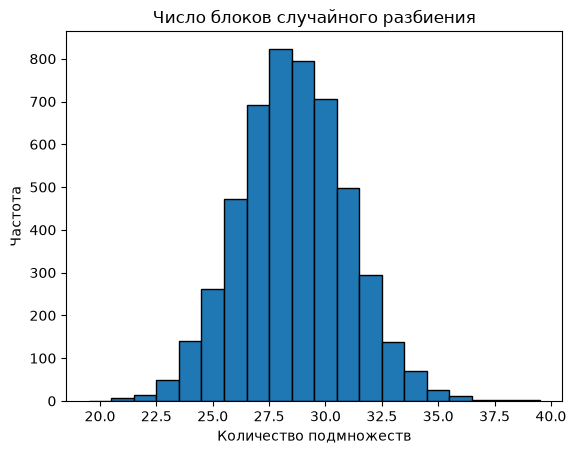

In [38]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import gammaln

n = 100

m = np.arange(1, 201)

log_weights = n * np.log(m) - gammaln(m + 1)

weights = np.exp(log_weights - max(log_weights))
p = weights / np.sum(weights)

def random_partition(n):
    M = np.random.choice(m, p=p)

    boxes = np.random.randint(0, M, size=n)

    partition = []

    for j in np.unique(boxes):
        block = np.where(boxes == j)[0] + 1
        partition.append(block.tolist())

    return partition

partition = random_partition(n)

print("Число подмножеств:", len(partition))
print("Первые 5 подмножеств:", partition[:5])

counts = []

for i in range(5000):
    partition = random_partition(n)
    counts.append(len(partition))

print("Оценка среднего числа подмножеств:", np.mean(counts))

plt.hist(counts, bins=np.arange(min(counts), max(counts)+2)-0.5,
         edgecolor='black')

plt.xlabel("Количество подмножеств")
plt.ylabel("Частота")
plt.title("Число блоков случайного разбиения")
plt.show()
